# Introduction to Python Project : FoodHub Data Analysis

### Problem Statement:-
The rapid growth of restaurants in New York has led to an increased reliance on online food delivery platforms like FoodHub, especially among students and working professionals with busy lifestyles. FoodHub connects customers with multiple restaurants and manages the end-to-end delivery process through its platform.

However, with increasing competition and order volumes, it becomes crucial for FoodHub to analyze its order data to understand customer preferences, restaurant demand, delivery efficiency, and factors influencing customer satisfaction.

The objective of this analysis is to explore the dataset of food orders to identify key patterns and relationships between variables such as cuisine type, cost of orders, delivery time, preparation time, and customer ratings. These insights will help the company:

Improve customer experience
Optimize delivery operations
Identify high-demand cuisines and restaurants
Enhance overall business performance and revenue

Thus, the problem focuses on leveraging data-driven insights to support better decision-making and strategic improvements for the FoodHub platform.




### Data Dictionary

*   order_id: Unique ID of the order
*   customer_id: ID of the customer who ordered the food
*   customer_id: ID of the customer who ordered the food
*   cuisine_type: Cuisine ordered by the customer
*   cost_of_the_order: Cost of the order
*   day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
*   rating: Rating given by the customer out of 5
*   food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
*   delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information







### Let us start by importing the required libraries

In [92]:
# importing necessary libraries for the project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [93]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [94]:
# Path to read the foodhub_order.csv file
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/foodhub_order.csv")

In [95]:
# Code to view the first 5 rows
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [96]:
df.shape

(1898, 9)

#### Observations: Total **1898** rows and **9** columns are present in the data

> Add blockquote




### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [97]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations: There are **3 datatypes** in 9 columns in the dataset
*   float64(1)
*   int64(4)
*   object(4)






### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [98]:
df.isnull().sum()

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


#### Observations:There are **No missing values** in the data.


### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [99]:
# Statistical summary of the data for all the columns
df.describe(include='all')

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
count,1.898000e+03,1898.000000,1898,1898,1898.000000,1898,1898,1898.000000,1898.000000
unique,NaN,NaN,178,14,NaN,2,4,NaN,NaN
top,NaN,NaN,Shake Shack,American,NaN,Weekend,Not given,NaN,NaN
freq,NaN,NaN,219,584,NaN,1351,736,NaN,NaN
mean,1.477496e+06,171168.478398,NaN,NaN,16.498851,NaN,NaN,27.371970,24.161749
std,5.480497e+02,113698.139743,NaN,NaN,7.483812,NaN,NaN,4.632481,4.972637
min,1.476547e+06,1311.000000,NaN,NaN,4.470000,NaN,NaN,20.000000,15.000000
25%,1.477021e+06,77787.750000,NaN,NaN,12.080000,NaN,NaN,23.000000,20.000000
50%,1.477496e+06,128600.000000,NaN,NaN,14.140000,NaN,NaN,27.000000,25.000000
75%,1.477970e+06,270525.000000,NaN,NaN,22.297500,NaN,NaN,31.000000,28.000000


#### Observations: Food Preparation Time
*   Minimum:- 20 mins
*   Average:- 27 mins
*   Maximum:- 35 mins






### **Question 5:** How many orders are not rated? [1 mark]

In [100]:
not_rated = df[df.rating=='Not given']
len(not_rated)

736

#### Observations: 736 orders are not rated


### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

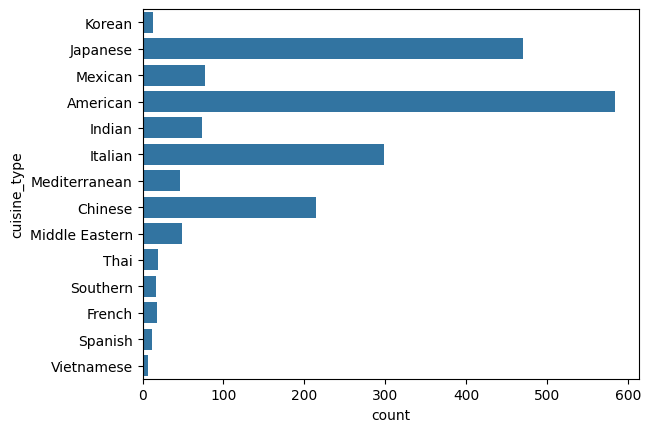

In [101]:
# code for cusine_type countplot
sns.countplot(df['cuisine_type'])
plt.show()


Obeservation:- The 4 most popular foor cuisines are Japanese, American, Italian and Chinese.

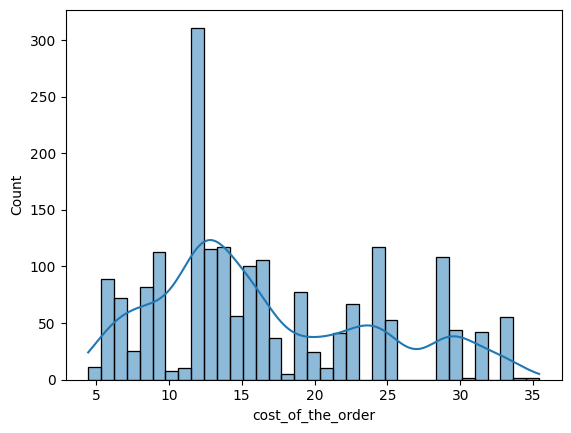

In [102]:
# code for cost_of_the_order histogram
sns.histplot(data=df,x='cost_of_the_order',bins= 35, kde=True);
plt.show()

Observation:- Maximum times customers have a cost of order around 12 dollars followed by 25 and 30 dollars.



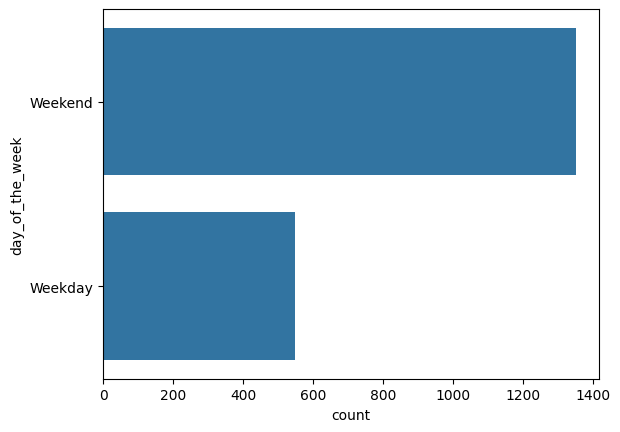

In [103]:
# code for day_of_the_week countplot
sns.countplot(df['day_of_the_week'])
plt.show()

Observation:- Maximum orders are on the weekend

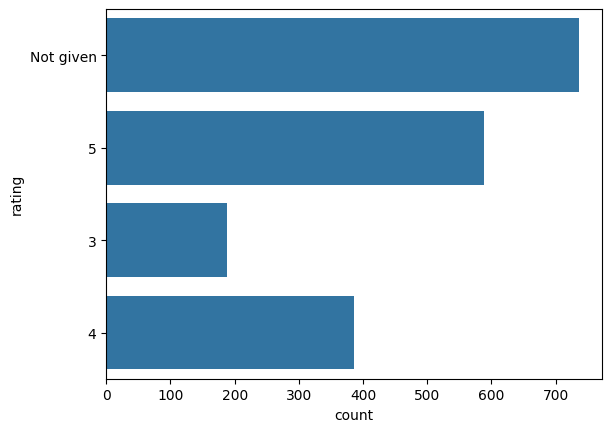

In [104]:
# code for rating countplot
sns.countplot(df['rating'])
plt.show()

Observation:- More than 700 customers have not given the rating,  around 600 customers have given 5 star rating, around 400 gave 4 star and around 200 customers gave 3 star rating

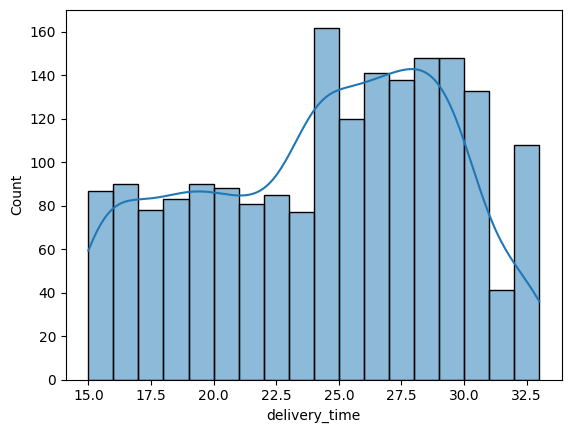

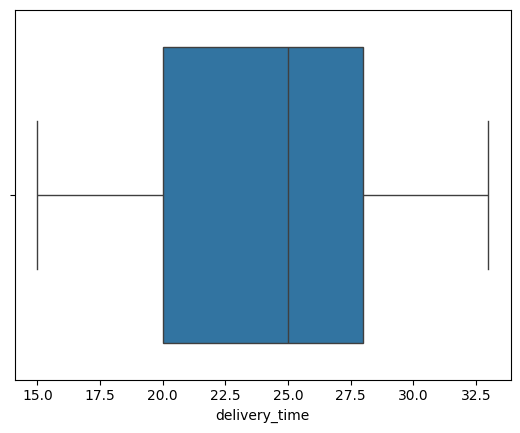

In [105]:
# code for delivery_time histogram and boxplot
sns.histplot(data=df,x='delivery_time', binwidth = 1, kde=True, stat="count")
plt.show()
sns.boxplot(data=df,x='delivery_time')
plt.show()


Observation:- The most occurrences of delivery time is 24-25 minutes, in the boxplot the data is slightly skewed to the left and delivery time between 24-31 minutes had an increased in counts to 120-160 times.

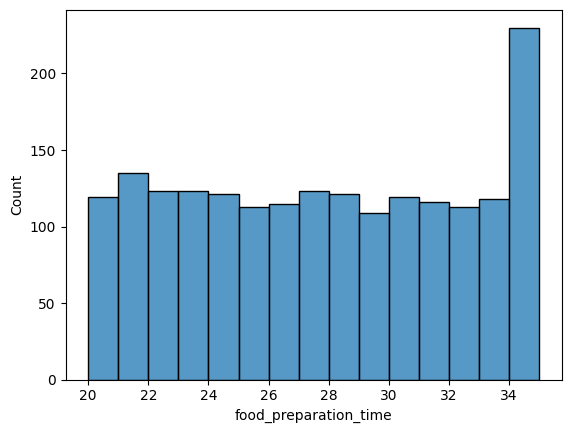

In [106]:
# code for food_preparation histogram
sns.histplot(data=df,x='food_preparation_time', binwidth=1 , stat="count")
plt.show()

Observation:- More than 200 orders have a food preparation time of 35 mins

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [107]:
# Code for top 5 restaurants in terms of number of orders received
df['restaurant_name'].value_counts().nlargest(10)

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68
RedFarm Broadway,59
RedFarm Hudson,55
TAO,49
Han Dynasty,46


#### Observations: Top 5 restaurants in terms of number of orders are: Shake Shack , The Meatball Shop , Blue Ribbon Sushi , Blue Ribbon Fried Chicken and Parm


### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

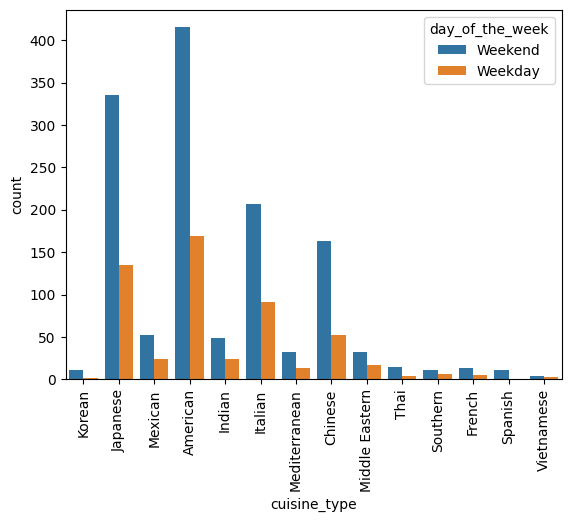

In [108]:
# code for the countplot for most popular cuisine on weekends
sns.countplot(data=df,x='cuisine_type', hue='day_of_the_week')
plt.xticks(rotation=90);
plt.show()

#### Observations: As per the data American cuisine is most popular on weekends


### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [109]:
# Code for percentage of the orders cost more than 20 dollars
round((len(df[df['cost_of_the_order']>20])/len(df))*100,2)

29.24

#### Observations: 29.24% of orders cost more than 20 dollars


### **Question 10**: What is the mean order delivery time? [1 mark]

In [110]:
# Code for mean order delivery time
round( df['delivery_time'].mean(),1)

np.float64(24.2)

#### Observations: Mean order delivery time is 24.2 mins


### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [111]:
# Code for top 3 most frequent customers.
df['customer_id'].value_counts().nlargest(3)

,count
customer_id,
52832,13
47440,10
83287,9


#### Observations: The top 3 most frequent customers are-


*   52832:- 13 orders
*   47440:- 10 orders
*   83827:- 9 orders






### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


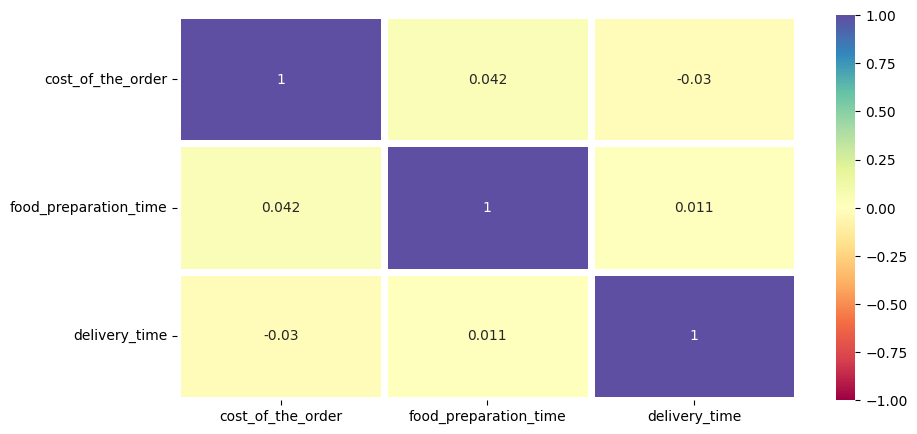

In [112]:
# Code for multivariate analysis to explore relationships between the important variables in the dataset
col_list = ['cost_of_the_order','food_preparation_time','delivery_time']
plt.figure(figsize=(10,5))
sns.heatmap(df[col_list].corr(),annot=True,cmap='Spectral',vmin=-1,vmax=1,linewidths=5)
plt.show()

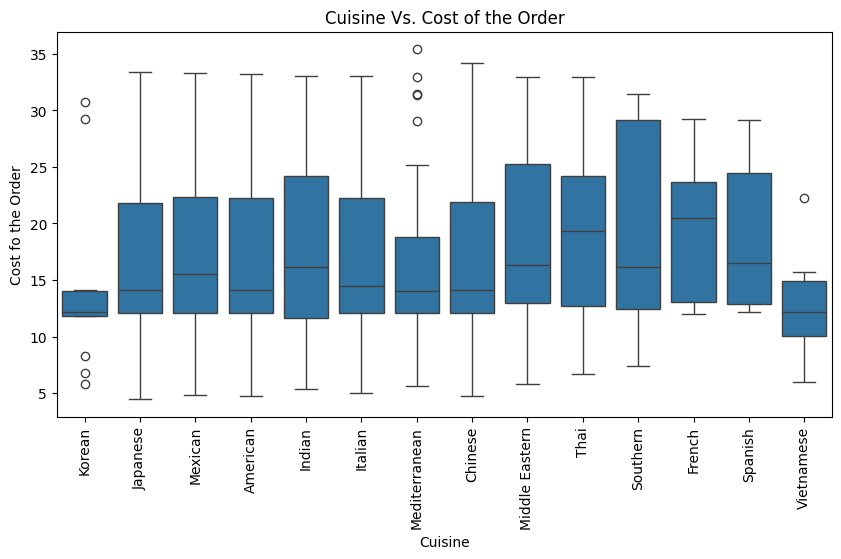

In [113]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df,x='cuisine_type',y='cost_of_the_order')
plt.xticks(rotation=90);
plt.title('Cuisine Vs. Cost of the Order')
plt.xlabel('Cuisine')
plt.ylabel('Cost fo the Order')
plt.show()

/tmp/ipykernel_2139/1612418542.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=df,x='day_of_the_week',y='food_preparation_time',ci=None)
/tmp/ipykernel_2139/1612418542.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=df,x='day_of_the_week',y='delivery_time',ci=None, linestyle='dotted')


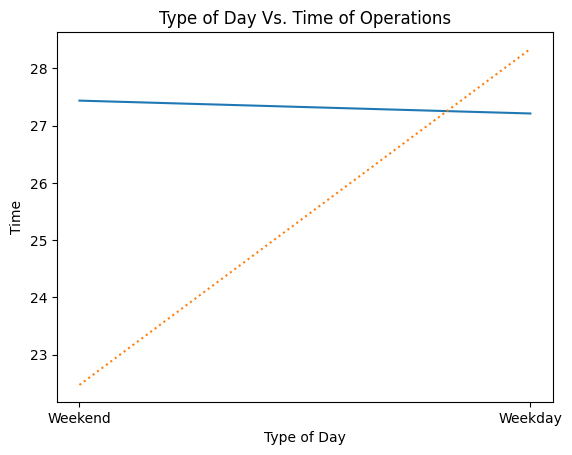

In [114]:
sns.lineplot(data=df,x='day_of_the_week',y='food_preparation_time',ci=None)

sns.lineplot(data=df,x='day_of_the_week',y='delivery_time',ci=None, linestyle='dotted')
plt.title('Type of Day Vs. Time of Operations')
plt.xlabel('Type of Day')
plt.ylabel('Time')
plt.show();

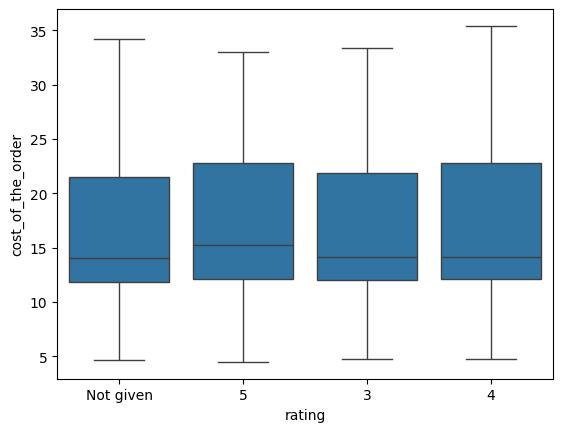

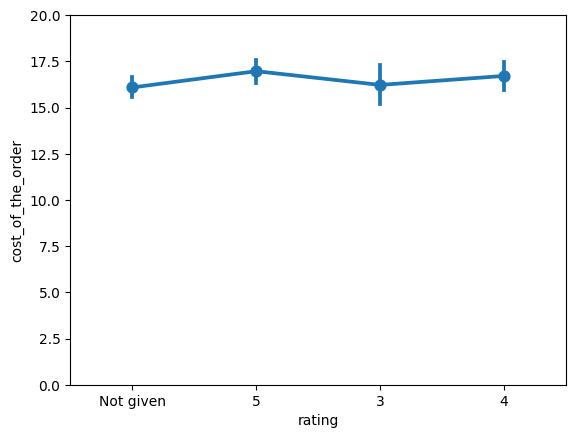

In [115]:
sns.boxplot(data=df, x='rating', y ='cost_of_the_order')
plt.yticks(rotation=0);
plt.show()
plt.figure()
sns.pointplot(data= df, x = 'rating', y = 'cost_of_the_order')
plt.ylim(0,20)
plt.show()

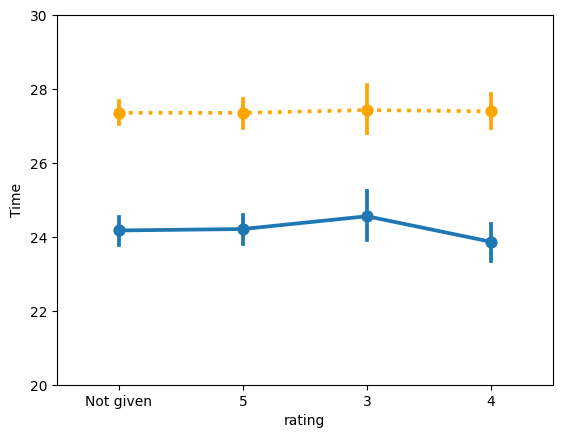

In [116]:
plt.figure()
sns.pointplot(data= df, x = 'rating', y = 'delivery_time')
sns.pointplot(data= df, x = 'rating', y = 'food_preparation_time', color = 'orange' ,linestyles= 'dotted')
plt.ylabel('Time')
plt.ylim(20,30)
plt.show()

Observations:

* There is no correlation between cost of the order, food preparation time, and delivery time, indicating these variables do not influence each other.

* Order ID and Customer ID are identifiers, so they are not relevant for correlation analysis.

* Most cuisines have an average order cost between 10 dollars and 25 dollars, showing a consistent pricing range across cuisines.

* A few outliers in cost exist, which may be due to different customer preferences or ordering habits.

* Food preparation time remains almost constant across weekdays and weekends.
Delivery time is shorter on weekends by 5 mins, indicating better efficiency or lower traffic conditions.

* There is no significant relationship between order cost and customer ratings, meaning higher spending does not guarantee better ratings.

* Ratings are mostly concentrated around orders costing 16 dollars to 17 dollars, showing a central tendency.

* Delivery time and food preparation time do not affect ratings, indicating customers are not highly sensitive to time delays.

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [117]:
# Code to find top restaurants with rating count more than 50 and average rating greater than 4
df2 = df.groupby(['restaurant_name'])['rating'].value_counts()
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
rest_rating = df.groupby(['restaurant_name'])['rating'].agg(['mean','count'])
rest_rating =  rest_rating[(rest_rating['mean'] > 4) & (rest_rating['count'] > 50)]
rest_rating

,mean,count
restaurant_name,,
Blue Ribbon Fried Chicken,4.328125,64
Blue Ribbon Sushi,4.219178,73
Shake Shack,4.278195,133
The Meatball Shop,4.511905,84


#### Observations:  The Meatball Shop, Blue Ribbon Fried Chicken, Blue Ribbon Sushi and Shake Shack are the only restaurants that had over 50 orders with average rating above 4.


### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [118]:
# Code for cost greater the 20 dollars
df5 = df[df.cost_of_the_order>20]
amount1 = df5.cost_of_the_order.sum()*.25

# Code for cost greater the 5 dollars but less than 20 dollars
df6=df[df.cost_of_the_order<=20]
amount2=df6[df6.cost_of_the_order>5].cost_of_the_order.sum()*.15

net_revenue = amount1 + amount2
print(round(net_revenue,2))

6166.3


#### Observations: Net revenue generated by the company across all orders is 6166.3 dollars


### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [119]:
# Code to analyze the total time required to deliver the food and percentage of orders take more than 60 mins to get delivered
df['total_time'] = df['food_preparation_time'] + df['delivery_time']
round((len(df[df['total_time']>60])/len(df))*100,1)

10.5

#### Observations: 10.5% of orders take more than 60 minutes to get delivered from the time the order is placed


### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

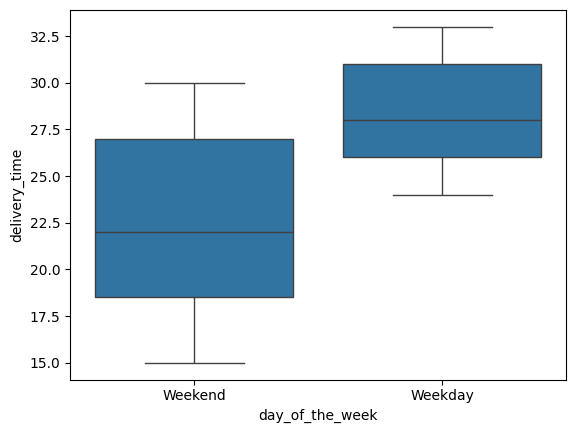

In [120]:
# Code for boxplot

sns.boxplot(data=df,x='day_of_the_week',y='delivery_time')
plt.show()

(0.0, 30.0)

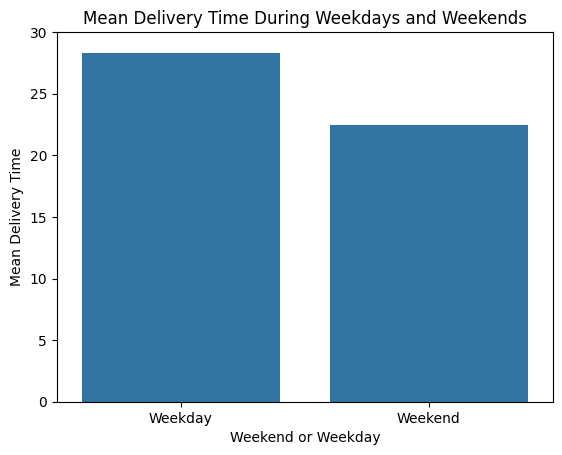

In [121]:
# Code for barplot

mean_delivery = df.groupby(['day_of_the_week'])['delivery_time'].mean()
sns.barplot(x=mean_delivery.index, y=mean_delivery.values)

plt.title('Mean Delivery Time During Weekdays and Weekends')
plt.xlabel('Weekend or Weekday')
plt.ylabel('Mean Delivery Time')
plt.ylim(0, 30)

In [122]:
print(mean_delivery)

day_of_the_week
Weekday    28.340037
Weekend    22.470022
Name: delivery_time, dtype: float64


#### Observations: Mean delivery time during weekday is 28.34 mins which is almost 6 mins higher than weekend i.e 22.47 mins


### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:
*  The most popular cuisines are Japanese, American, Italian, and Chinese, each with high order volumes.

* Demand is higher on weekends, indicating peak ordering periods.

* Weekday delivery times are longer than weekends, showing operational inefficiencies.

### Recommendations:

*  Improve weekday delivery efficiency by optimizing logistics and staffing.

* Expand and promote top-performing cuisines to capture more demand.

* Focus on reducing extreme delays (over 60 minutes) rather than increasing weekend delivery capacity, as ratings are not heavily impacted by delivery time.